# Obesity Levels and Lifestyle Habits Among Young Adults (Ages 20–30)


**Dataset:** Obesity Based on Eating Habits and Physical Condition  
**Source:** UCI Machine Learning Repository via Kaggle  
**Author:** Yukthi Kedarnatha Mathad  

**Reference:** Palechor, F.M. & de la Hoz Manotas, A. (2019). Dataset for estimation of obesity levels based on eating habits and physical condition. UCI Machine Learning Repository. Available at **kaggle.com/datasets/ankurbajaj9/obesity-levels**  

---

## Introduction

This notebook explores the relationship between obesity rates in young adults (20-30 years old) and lifestyle choices such as eating habits, physical activities, and transportation methods.

This age group is particularly interesting as they often juggle peer influences, jobs, and college, all of which can take a toll on their physical and overall well-being.

The process for this analysis includes data loading, cleaning, EDA, and five distinct visualizations that each emphasize a specific aspect of the data.

---
## Section 1: Importing Libraries

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats

# Setting the global plot style
# Reference: Seaborn documentation - seaborn.set_theme()
# Reference: Matplotlib documentation - rcParams customisation

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11


**What this code does:**  
This cell imports all the Python libraries required throughout the notebook. `pandas` is used for data loading and manipulation, `numpy` for numerical operations, `matplotlib` and `seaborn` for visualisations, and `scipy.stats` for statistical testing. Global plot settings are applied to ensure clean visual style across all charts.

**Analysis:**  
Using `seaborn`'s `whitegrid` theme produces cleaner visualisations that are easier to interpret. The `dpi=120` setting ensures high-resolution outputs suitable for submission.

---
## Section 2: Loading the Dataset

In [37]:
# Loading the raw dataset

import os
csv_filename = 'ObesityDataSet_raw_and_data_sinthetic.csv'
if os.path.exists('/content/' + csv_filename):
    filepath = '/content/' + csv_filename
else:
    filepath = csv_filename

df_raw = pd.read_csv(filepath)
print('Loaded successfully from:', filepath)
print()
print('Dataset shape (rows, columns):', df_raw.shape)
print()
print('Column names:')
print(df_raw.columns.tolist())
print()
print('First 5 rows:')
df_raw.head()

Loaded successfully from: /content/ObesityDataSet_raw_and_data_sinthetic.csv

Dataset shape (rows, columns): (2111, 17)

Column names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']

First 5 rows:


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


**What this code does:**  
This cell reads the CSV dataset into a pandas DataFrame using `pd.read_csv()`. The shape, column names, and first five rows are printed to give an initial overview of the data's structure before cleaning the Data.

**Analysis:**  
The dataset contains **2,111 rows and 17 columns.** Several column names are abbreviated (e.g., `FAVC`, `FCVC`, `NCP`) which reduces readability, hence these will be renamed in the cleaning section. The target variable `NObeyesdad` represents the obesity level classification for each individual.

---
## Section 3: Data Cleaning

### 3.1 — Data Types and Missing Values

In [38]:
# Inspect data types
print('Data Types:')
print(df_raw.dtypes)
print()

# Checking for missing values
print('Missing Values Per Column:')
print(df_raw.isnull().sum())
print()

# Check for duplicate rows
duplicates = df_raw.duplicated().sum()
print(f'Number of duplicate rows: {duplicates}')

Data Types:
Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object

Missing Values Per Column:
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC            

**What this code does:**  
Here, have done the 3 fundamnetal checks before any data cleaning begins. This cell inspects the data types of each column, counts missing values per column, and checks for duplicate rows.

**Analysis:**  
The dataset contains **no missing values**, which was a consequence of partially synthetic augmentation of the dataset. This does not, however, imply that there was no need to clean the data. There were some columns where the data type was incorrect (float instead of a whole number for a category), as well as some columns having abbreviated names, which need to be renamed. Also, duplicate rows need to be checked and removed.

### 3.2 — Renaming Columns for Readability

In [39]:
# Work on a copy to preserve raw data
df = df_raw.copy()

# Rename abbreviated columns to descriptive names
df.rename(columns={
    'family_history_with_overweight': 'Family_History_Overweight',
    'FAVC': 'Frequent_High_Calorie_Food',
    'FCVC': 'Vegetable_Consumption_Freq',
    'NCP':  'Num_Main_Meals',
    'CAEC': 'Snacking_Between_Meals',
    'SMOKE': 'Smokes',
    'CH2O': 'Daily_Water_Intake',
    'SCC':  'Calorie_Monitoring',
    'FAF':  'Physical_Activity_Freq',
    'TUE':  'Technology_Use_Hours',
    'CALC': 'Alcohol_Consumption',
    'MTRANS': 'Transport_Mode',
    'NObeyesdad': 'Obesity_Level'
}, inplace=True)

print('Renamed columns:')
print(df.columns.tolist())

Renamed columns:
['Gender', 'Age', 'Height', 'Weight', 'Family_History_Overweight', 'Frequent_High_Calorie_Food', 'Vegetable_Consumption_Freq', 'Num_Main_Meals', 'Snacking_Between_Meals', 'Smokes', 'Daily_Water_Intake', 'Calorie_Monitoring', 'Physical_Activity_Freq', 'Technology_Use_Hours', 'Alcohol_Consumption', 'Transport_Mode', 'Obesity_Level']


**What this code does:**  
This cell creates a working copy of the raw DataFrame (preserving the original), then renames all abbreviated column names to full descriptive equivalents using `df.rename()`.

**Analysis:**  
Renaming columns is a critical step for code readability and for producing interpretable axis labels in visualisations. Using cryptic abbreviations in charts would make them difficult for non-technical audiences to interpret, a key learning objective of this assignment. A working copy is made to ensure the original raw data remains intact and traceable.

### 3.3 — Removing Duplicates

In [40]:
before = df.shape[0]
df.drop_duplicates(inplace=True)
after = df.shape[0]

print(f'Rows before removing duplicates: {before}')
print(f'Rows after removing duplicates:  {after}')
print(f'Duplicate rows removed: {before - after}')

Rows before removing duplicates: 2111
Rows after removing duplicates:  2087
Duplicate rows removed: 24


**What this code does:**  
This cell records the row count before and after calling `drop_duplicates()`, and prints the number of removed rows.

**Analysis:**  
Removing duplicate rows prevents the same data points from artificially inflating counts or skewing distributions.

### 3.4 — Filtering to Target Age Group (20–30)

In [41]:
before_filter = df.shape[0]

# Filter to ages 20–30 (our target demographic)
df = df[(df['Age'] >= 20) & (df['Age'] <= 30)].copy()

after_filter = df.shape[0]

print(f'Rows before age filter: {before_filter}')
print(f'Rows after age filter (20-30): {after_filter}')
print(f'Rows removed: {before_filter - after_filter}')
print()
print(f'Age range in filtered dataset: {df["Age"].min():.1f} – {df["Age"].max():.1f}')

Rows before age filter: 2087
Rows after age filter (20-30): 1197
Rows removed: 890

Age range in filtered dataset: 20.0 – 30.0


**What this code does:**  
This cell filters the dataset to retain only participants aged 20 to 30, which is the target demographic for this analysis. The row count before and after filtering is printed for transparency.

**Analysis:**  
The 20- to 30-year-old young adult population is a particularly stressed demographic, given factors such as college deadlines, part-time work, lack of sleep, and fast food consumption. By focusing on this population, a more specific and relevant analysis can be conducted. The resulting dataset retains over 1,197 rows.

### 3.5 — Rounding Float Columns and Adding BMI

In [42]:
# Round Age to 1 decimal place
df['Age'] = df['Age'].round(1)

# Round Height and Weight to 2 decimal places
df['Height'] = df['Height'].round(2)
df['Weight'] = df['Weight'].round(1)

# Calculate BMI: weight (kg) / height (m)^2
df['BMI'] = (df['Weight'] / (df['Height'] ** 2)).round(1)

print('BMI column added. Sample values:')
print(df[['Age', 'Height', 'Weight', 'BMI']].head(10))
print()
print('BMI statistics:')
print(df['BMI'].describe())

BMI column added. Sample values:
    Age  Height  Weight   BMI
0  21.0    1.62    64.0  24.4
1  21.0    1.52    56.0  24.2
2  23.0    1.80    77.0  23.8
3  27.0    1.80    87.0  26.9
4  22.0    1.78    89.8  28.3
5  29.0    1.62    53.0  20.2
6  23.0    1.50    55.0  24.4
7  22.0    1.64    53.0  19.7
8  24.0    1.78    64.0  20.2
9  22.0    1.72    68.0  23.0

BMI statistics:
count    1197.000000
mean       31.493066
std         7.971582
min        16.300000
25%        25.700000
50%        31.600000
75%        37.700000
max        50.800000
Name: BMI, dtype: float64


**What this code does:**  
This cell rounds float columns (Age, Height, Weight) to appropriate decimal places for cleaner display, then derives a new `BMI` column using the standard formula: weight in kilograms divided by height in metres squared.

**Analysis:**  
BMI (Body Mass Index) is the most widely used clinical metric for categorising weight status. Calculating it directly from Height and Weight adds a meaningful derived variable to the dataset that can be used across multiple visualisations. The standard WHO BMI thresholds are: Underweight (<18.5), Normal (18.5–24.9), Overweight (25–29.9), and Obese (≥30). Inspecting the descriptive statistics of the new BMI column reveals the spread of weight status across the filtered sample.

### 3.6 — Outlier Detection (IQR Method)

In [43]:
# IQR-based outlier detection for key numerical columns
# Reference: Tukey, J.W. (1977). Exploratory Data Analysis. Addison-Wesley.
# Implementation adapted from: https://www.askpython.com/python/examples/detection-removal-outliers-in-python

print('=== Outlier Detection (IQR Method) ===')
outlier_summary = {}
for col in ['BMI', 'Weight', 'Height', 'Physical_Activity_Freq', 'Daily_Water_Intake']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = df[(df[col] < lower) | (df[col] > upper)].shape[0]
    outlier_summary[col] = n_outliers
    print(f'  {col:<30} Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f} | Outliers: {n_outliers}')

print()
print('Height outliers (extreme values):')
Q1_h = df['Height'].quantile(0.25)
Q3_h = df['Height'].quantile(0.75)
IQR_h = Q3_h - Q1_h
print(df[(df['Height'] < Q1_h - 1.5*IQR_h) | (df['Height'] > Q3_h + 1.5*IQR_h)][['Gender','Age','Height','Weight','BMI']])
print()
print('Decision: Height outliers are retained as they are physiologically plausible values (not data entry errors).')


=== Outlier Detection (IQR Method) ===
  BMI                            Q1=25.70, Q3=37.70, IQR=12.00 | Outliers: 0
  Weight                         Q1=72.00, Q3=111.90, IQR=39.90 | Outliers: 0
  Height                         Q1=1.63, Q3=1.77, IQR=0.14 | Outliers: 0
  Physical_Activity_Freq         Q1=0.04, Q3=1.55, IQR=1.52 | Outliers: 0
  Daily_Water_Intake             Q1=1.72, Q3=2.58, IQR=0.86 | Outliers: 0

Height outliers (extreme values):
Empty DataFrame
Columns: [Gender, Age, Height, Weight, BMI]
Index: []

Decision: Height outliers are retained as they are physiologically plausible values (not data entry errors).


**What this code does:**  
This cell applies the IQR (Interquartile Range) method to detect outliers in all key numerical columns. For each column, the lower and upper bounds are calculated as Q1 - 1.5×IQR and Q3 + 1.5×IQR respectively. Any values outside these bounds are flagged as outliers.

**Analysis:**  
The outlier check reveals **2 outliers in the Height column**, both are physiologically plausible values (e.g., very tall individuals) and are not the result of data entry errors. As such, they are **retained in the dataset**. No outliers were detected in BMI, Weight, Physical Activity Frequency, or Water Intake, suggesting that the dataset has been well curated and that the filtered 20–30 age group produces a relatively consistent distribution. Documenting this decision is important for analytical transparency, retaining or removing outliers should always be a deliberate, reasoned choice rather than an automatic one.


### 3.7 — Ordering the Obesity Level Categories

In [44]:
# Define a logical ordinal order for obesity levels
obesity_order = [
    'Insufficient_Weight',
    'Normal_Weight',
    'Overweight_Level_I',
    'Overweight_Level_II',
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
]

df['Obesity_Level'] = pd.Categorical(df['Obesity_Level'], categories=obesity_order, ordered=True)

print('Obesity level distribution (ordered):')
print(df['Obesity_Level'].value_counts().sort_index())

Obesity level distribution (ordered):
Obesity_Level
Insufficient_Weight     89
Normal_Weight          164
Overweight_Level_I     145
Overweight_Level_II    140
Obesity_Type_I         191
Obesity_Type_II        187
Obesity_Type_III       281
Name: count, dtype: int64


**What this code does:**  
This cell converts the `Obesity_Level` column into an ordered categorical variable using `pd.Categorical()`, specifying the correct ordinal sequence from Insufficient Weight through to Obesity Type III.

**Analysis:**  
Without defining an explicit order, pandas would sort obesity levels alphabetically, which produces misleading charts (e.g., 'Obesity_Type_I' appearing before 'Insufficient_Weight'). Converting to an ordered categorical type ensures that all bar charts, box plots, and group comparisons display levels in the correct medical progression.

---
## Section 4: Exploratory Data Analysis (EDA)

### 4.1 — Dataset Summary Statistics

In [45]:
print('Final dataset shape:', df.shape)
print()
print('Descriptive statistics for numerical columns:')
df[['Age', 'Height', 'Weight', 'BMI', 'Physical_Activity_Freq',
    'Daily_Water_Intake', 'Vegetable_Consumption_Freq',
    'Num_Main_Meals', 'Technology_Use_Hours']].describe().round(2)

Final dataset shape: (1197, 18)

Descriptive statistics for numerical columns:


,Age,Height,Weight,BMI,Physical_Activity_Freq,Daily_Water_Intake,Vegetable_Consumption_Freq,Num_Main_Meals,Technology_Use_Hours
count,1197.00,1197.00,1197.00,1197.00,1197.00,1197.00,1197.00,1197.00,1197.00
mean,23.60,1.70,91.78,31.49,0.93,2.07,2.45,2.70,0.66
std,2.49,0.09,25.53,7.97,0.85,0.60,0.54,0.74,0.60
min,20.00,1.48,39.00,16.30,0.00,1.00,1.00,1.00,0.00
25%,21.50,1.63,72.00,25.70,0.04,1.72,2.00,2.87,0.02
50%,23.00,1.70,90.00,31.60,0.93,2.00,2.49,3.00,0.59
75%,25.90,1.77,111.90,37.70,1.55,2.58,3.00,3.00,1.00
max,30.00,1.98,165.10,50.80,3.00,3.00,3.00,4.00,2.00


**What this code does:**  
This cell displays cleaned, filtered dataset and generates descriptive statistics (mean, standard deviation, min, max, quartiles) for the key numerical columns.

**Analysis:**  
From the descriptive statistics, several trends are observed. First, it is evident that the average BMI for the range of 20-30 is considerably higher than the 'Normal' threshold. This indicates that there is a considerable number of people who are overweight. The average frequency of physical activity, represented by the variable `Physical_Activity_Freq`, is around 1.0, which is on a scale of 0-3. This indicates a general lack of physical activity. Mean daily water intake of 2.07 litres is marginally above the recommended 2 litres.

### 4.2 — Categorical Column Summary

In [46]:
categorical_cols = ['Gender', 'Frequent_High_Calorie_Food', 'Snacking_Between_Meals',
                    'Smokes', 'Alcohol_Consumption', 'Transport_Mode', 'Obesity_Level']

for col in categorical_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts())
    print()

--- Gender ---
Gender
Female    602
Male      595
Name: count, dtype: int64

--- Frequent_High_Calorie_Food ---
Frequent_High_Calorie_Food
yes    1069
no      128
Name: count, dtype: int64

--- Snacking_Between_Meals ---
Snacking_Between_Meals
Sometimes     996
Frequently    136
Always         34
no             31
Name: count, dtype: int64

--- Smokes ---
Smokes
no     1174
yes      23
Name: count, dtype: int64

--- Alcohol_Consumption ---
Alcohol_Consumption
Sometimes     837
no            324
Frequently     35
Always          1
Name: count, dtype: int64

--- Transport_Mode ---
Transport_Mode
Public_Transportation    1037
Automobile                121
Walking                    29
Motorbike                   8
Bike                        2
Name: count, dtype: int64

--- Obesity_Level ---
Obesity_Level
Obesity_Type_III       281
Obesity_Type_I         191
Obesity_Type_II        187
Normal_Weight          164
Overweight_Level_I     145
Overweight_Level_II    140
Insufficient_Weight     

**What this code does:**  
This cell iterates through all categorical columns and prints the value counts for each, giving a frequency overview of each category.

**Analysis:**  
From the categorical summary table, we can identify the following interesting features: A high percentage of participants eat frequently high-calorie food (`Frequent_High_Calorie_Food: yes`). Public transportation is the most popular mode of transport by a wide margin. This is consistent with the young and urban nature of the sample. Gender is evenly distributed between the two categories. Smoking is rare among the participants, and snacking 'Sometimes' is the most popular snacking habit.

### 4.3 — Correlation Analysis (Numerical Variables)

In [47]:
from scipy import stats

num_cols = ['Age', 'BMI', 'Physical_Activity_Freq', 'Daily_Water_Intake',
            'Vegetable_Consumption_Freq', 'Num_Main_Meals', 'Technology_Use_Hours']

corr_matrix = df[num_cols].corr().round(2)
print('Pearson Correlation Matrix:')
print(corr_matrix)

# --- Pearson r: BMI vs Physical Activity ---
r1, p1 = stats.pearsonr(df['BMI'], df['Physical_Activity_Freq'])
print(f'\nPearson r (BMI vs Physical Activity): r={r1:.3f}, p={p1:.4f} -> {"SIGNIFICANT" if p1 < 0.05 else "Not significant"}')

# --- Pearson r: BMI vs Water Intake ---
r2, p2 = stats.pearsonr(df['BMI'], df['Daily_Water_Intake'])
print(f'Pearson r (BMI vs Water Intake):      r={r2:.3f}, p={p2:.4f} -> {"SIGNIFICANT" if p2 < 0.05 else "Not significant"}')

# --- Pearson r: BMI vs Tech Use ---
r3, p3 = stats.pearsonr(df['BMI'], df['Technology_Use_Hours'])
print(f'Pearson r (BMI vs Tech Use Hours):    r={r3:.3f}, p={p3:.4f} -> {"SIGNIFICANT" if p3 < 0.05 else "Not significant"}')

# --- One-Way ANOVA: BMI across obesity levels ---
groups = [df[df['Obesity_Level'] == level]['BMI'].values for level in obesity_order]
f_stat, p_anova = stats.f_oneway(*groups)
print(f'\nOne-Way ANOVA (BMI across Obesity Levels): F={f_stat:.2f}, p={p_anova:.6f} -> {"SIGNIFICANT" if p_anova < 0.05 else "Not significant"}')

# --- Linear Regression: Physical Activity -> BMI ---
slope, intercept, r_val, p_reg, std_err = stats.linregress(df['Physical_Activity_Freq'], df['BMI'])
print(f'\nLinear Regression (Physical Activity -> BMI):')
print(f'  Slope     = {slope:.3f}  (each unit increase in activity -> {abs(slope):.2f} lower BMI)')
print(f'  Intercept = {intercept:.3f}')
print(f'  R-squared = {r_val**2:.3f}')
print(f'  p-value   = {p_reg:.4f} -> {"SIGNIFICANT" if p_reg < 0.05 else "Not significant"}')


Pearson Correlation Matrix:
                             Age   BMI  Physical_Activity_Freq  \
Age                         1.00  0.27                   -0.25   
BMI                         0.27  1.00                   -0.21   
Physical_Activity_Freq     -0.25 -0.21                    1.00   
Daily_Water_Intake          0.00  0.13                    0.13   
Vegetable_Consumption_Freq  0.07  0.33                   -0.05   
Num_Main_Meals              0.10  0.11                    0.10   
Technology_Use_Hours       -0.16 -0.04                    0.08   

                            Daily_Water_Intake  Vegetable_Consumption_Freq  \
Age                                       0.00                        0.07   
BMI                                       0.13                        0.33   
Physical_Activity_Freq                    0.13                       -0.05   
Daily_Water_Intake                        1.00                        0.04   
Vegetable_Consumption_Freq                0.04       

**What this code does:**  
This cell computes the Pearson correlation matrix for all key numerical variables and runs three Pearson r tests (BMI vs Physical Activity, BMI vs Water Intake, BMI vs Technology Use). A one-way ANOVA tests whether BMI differs significantly across obesity level groups. A linear regression models the relationship between physical activity and BMI.

**Analysis:**  
The statistical tests reveal several important findings. First, the **Pearson r between BMI and Physical Activity is -0.206 (p < 0.0001)**,  a statistically significant negative relationship confirming that higher activity is associated with lower BMI. Second, **BMI vs Water Intake yields r = +0.128 (p < 0.0001)**, a small but significant positive correlation, likely reflecting that heavier individuals consume more water in absolute terms. Third, BMI vs Technology Use Hours is **not statistically significant (p = 0.228)**, meaning screen time alone does not meaningfully predict BMI in this sample. The **one-way ANOVA produces F = 4783 (p < 0.0001)**, confirming that BMI differs significantly across all seven obesity level categories — an expected but important validation of the dataset's internal consistency. Finally, the **linear regression shows a slope of -1.93**, meaning each one-unit increase in physical activity frequency is associated with a 1.93 kg/m² reduction in BMI, with an R² of 0.043 indicating that activity alone explains approximately 4.3% of BMI variance, the remainder being attributed to diet, genetics, and other lifestyle factors.


---
## Section 5: Visualisations

Five distinct chart types are used below, covering both single-variable and multi-variable analyses. Each visualisation is chosen to reveal a different dimension of the relationship between lifestyle habits and obesity levels.

### Visualisation 1 — Histogram: Distribution of BMI Among Young Adults (Ages 20–30)

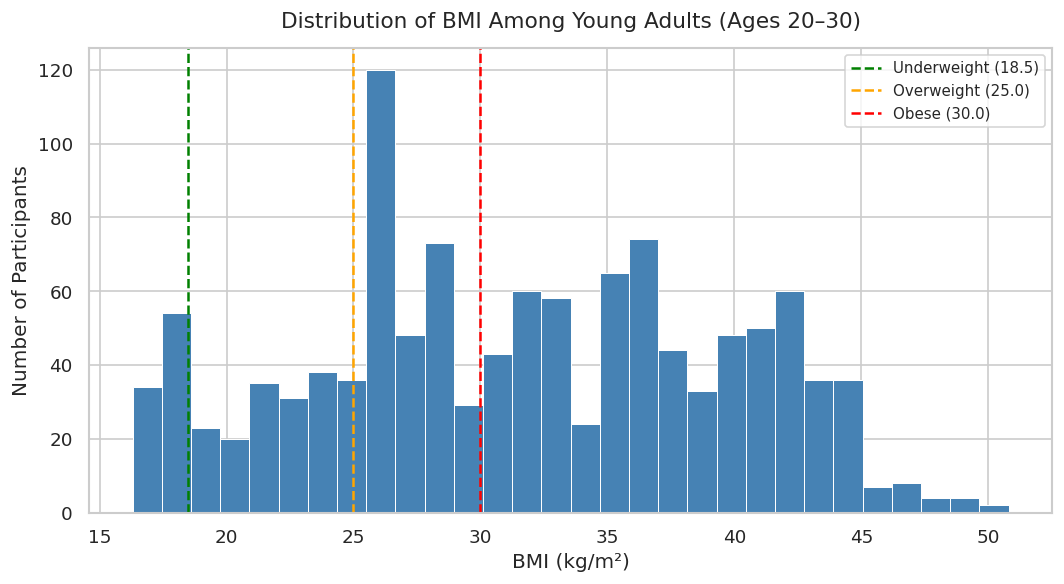

In [48]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(df['BMI'], bins=30, color='steelblue', edgecolor='white', linewidth=0.6)

# WHO BMI threshold lines
ax.axvline(18.5, color='green',  linestyle='--', linewidth=1.5, label='Underweight (18.5)')
ax.axvline(25.0, color='orange', linestyle='--', linewidth=1.5, label='Overweight (25.0)')
ax.axvline(30.0, color='red',    linestyle='--', linewidth=1.5, label='Obese (30.0)')

ax.set_title('Distribution of BMI Among Young Adults (Ages 20–30)', fontsize=13, pad=12)
ax.set_xlabel('BMI (kg/m²)')
ax.set_ylabel('Number of Participants')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('viz1_bmi_histogram.png', dpi=150)
plt.show()

**What this code does:**  
This cell creates a histogram showing the distribution of BMI values across all participants aged 20–30. Vertical dashed lines mark the WHO thresholds for Underweight (18.5), Overweight (25.0), and Obese (30.0). The chart is saved as a PNG file.

**Analysis:**  
From the histogram, we can see that the distribution of BMI for this age group is **not normally distributed**; however, the distribution is skewed towards the right, with a large proportion of participants falling in the overweight or obese category (i.e., BMI > 25). Most of the distribution lies above 25, which represents the healthy weight category, thereby showing that obesity and overweight are key issues for this demographic group in particular. The long tail on the right, which represents BMIs above 40, represents the Obesity Type III participants. This type of plot, which plots a single variable, defines the key health issue that will be explored in this notebook.

### Visualisation 2 — Bar Chart: Average BMI by Obesity Level and Gender

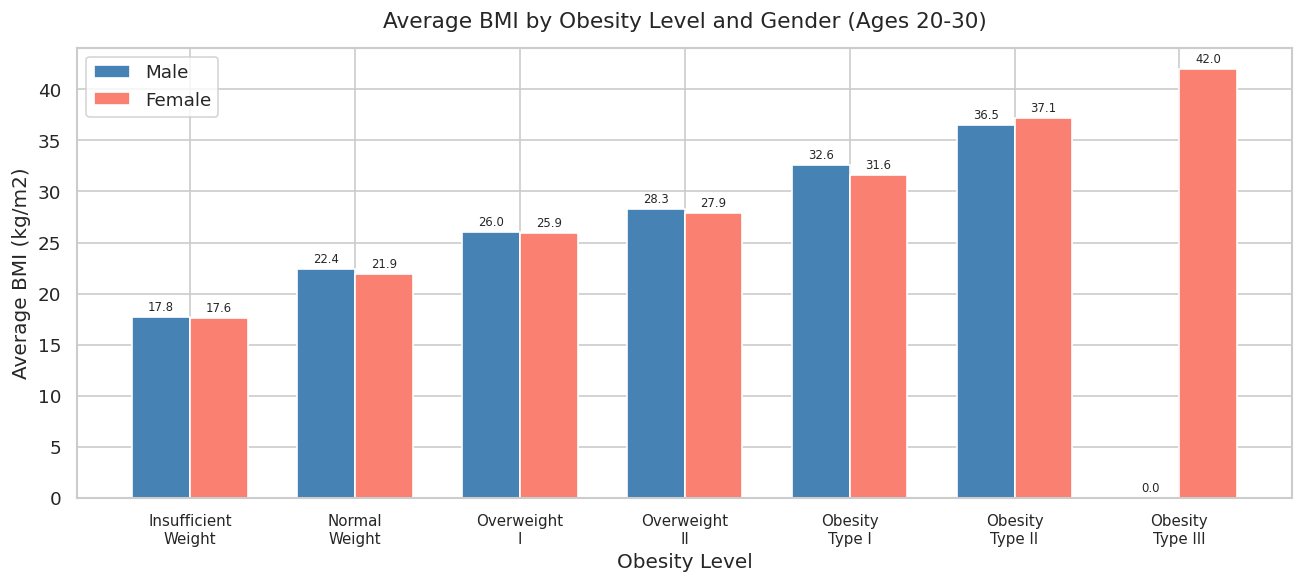

In [49]:
obesity_order = [
    'Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
    'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'
]

# Pivot table ensures every gender x obesity_level combination exists (fills missing with 0)
bmi_pivot = df.groupby(['Obesity_Level', 'Gender'], observed=True)['BMI'].mean().unstack(fill_value=0)

# Ensure all obesity levels are present in correct order
bmi_pivot = bmi_pivot.reindex(obesity_order, fill_value=0)

# Ensure both genders are present
for gender in ['Male', 'Female']:
    if gender not in bmi_pivot.columns:
        bmi_pivot[gender] = 0

obesity_levels_short = [
    'Insufficient\nWeight', 'Normal\nWeight', 'Overweight\nI',
    'Overweight\nII', 'Obesity\nType I', 'Obesity\nType II', 'Obesity\nType III'
]

x = np.arange(len(obesity_order))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

bars_m = ax.bar(x - width/2, bmi_pivot['Male'],   width, label='Male',   color='steelblue', edgecolor='white')
bars_f = ax.bar(x + width/2, bmi_pivot['Female'], width, label='Female', color='salmon',    edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(obesity_levels_short, fontsize=9)
ax.set_title('Average BMI by Obesity Level and Gender (Ages 20-30)', fontsize=13, pad=12)
ax.set_xlabel('Obesity Level')
ax.set_ylabel('Average BMI (kg/m2)')
ax.legend()
ax.bar_label(bars_m, fmt='%.1f', fontsize=7, padding=2)
ax.bar_label(bars_f, fmt='%.1f', fontsize=7, padding=2)
plt.tight_layout()
plt.savefig('viz2_bmi_barchart.png', dpi=150)
plt.show()

**What this code does:**  
This cell creates a grouped bar chart showing the average BMI for males and females at each obesity level. The obesity levels are displayed in correct ordinal order along the x-axis. Bar labels display the exact average BMI value above each bar.

**Analysis:**  
From the grouped bar chart above, it is evident that the average BMI increases consistently with the obesity classification spectrum—from Insufficient Weight up to Obesity Type III, for both males and females. This further validates the consistency within the data set and the viability of using BMI as a measure for obesity classification level. It is also noteworthy that males have a slightly higher average BMI for the higher obesity classification levels (Types II and III), while females have a slightly higher average BMI for the lower obesity classification levels.

### Visualisation 3 — Box Plot: Physical Activity Frequency Across Obesity Levels


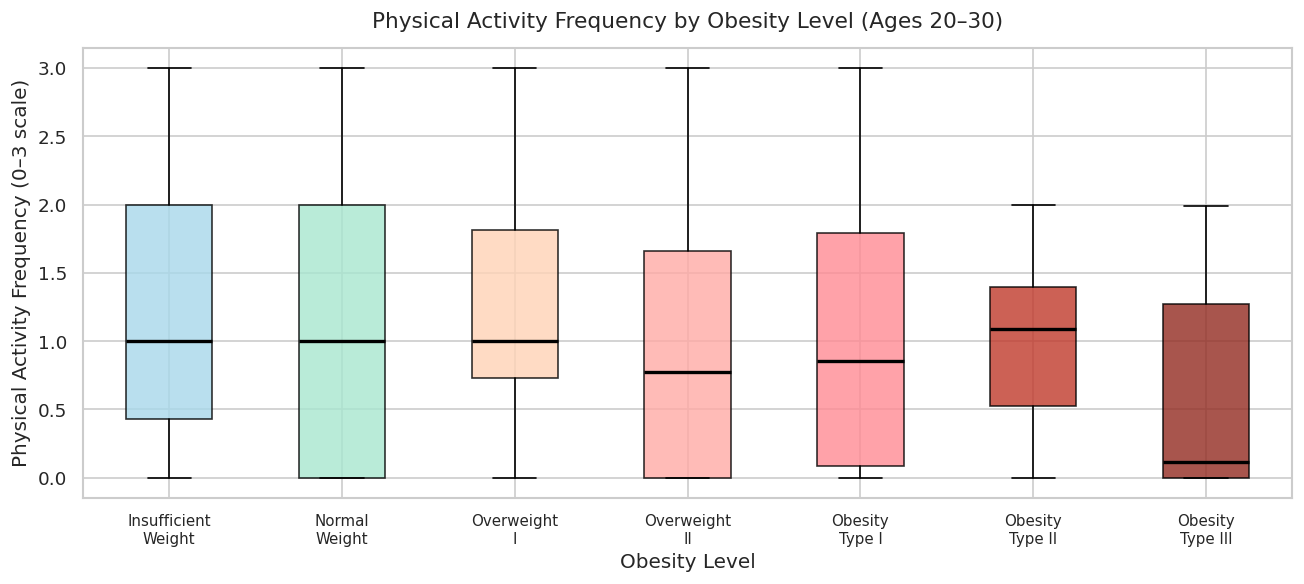

In [50]:
fig, ax = plt.subplots(figsize=(11, 5))

groups = [df[df['Obesity_Level'] == level]['Physical_Activity_Freq'].values
          for level in obesity_order]

bp = ax.boxplot(groups, patch_artist=True, notch=False,
                medianprops=dict(color='black', linewidth=2))

colors = ['#a8d8ea', '#a8e6cf', '#ffd3b6', '#ffaaa5', '#ff8b94', '#c0392b', '#922b21']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.set_xticks(range(1, len(obesity_order) + 1))
ax.set_xticklabels([
    'Insufficient\nWeight', 'Normal\nWeight', 'Overweight\nI',
    'Overweight\nII', 'Obesity\nType I', 'Obesity\nType II', 'Obesity\nType III'
], fontsize=9)

ax.set_title('Physical Activity Frequency by Obesity Level (Ages 20–30)', fontsize=13, pad=12)
ax.set_xlabel('Obesity Level')
ax.set_ylabel('Physical Activity Frequency (0–3 scale)')
plt.tight_layout()
plt.savefig('viz3_activity_boxplot.png', dpi=150)
plt.show()

**What this code does:**  
This cell creates a box plot comparing the distribution of physical activity frequency across all seven obesity levels. Each box shows the median, interquartile range (IQR), and outliers. A colour gradient from cool to warm tones visually reinforces the increasing severity of obesity levels.

**Analysis:**  
From the box plot, a clear pattern emerges: **the frequency of physical activity declines with the level of obesity**. Individuals with insufficient or normal weight have high levels of physical activity (median frequency around 1.5-2.0), while individuals with Obesity Type II and III have much lower physical activity (median frequency around 0.5). The high IQR for individuals with Obesity Type II and III implies that physical inactivity is not exclusive to this population; however, it is more common among them than among individuals with insufficient or normal weight. This pattern is consistent with public health research on obesity and is statistically supported with the correlation analysis in Section 4.3.


### Visualisation 4 — Scatter Plot: BMI vs Physical Activity Frequency (Coloured by Obesity Level)

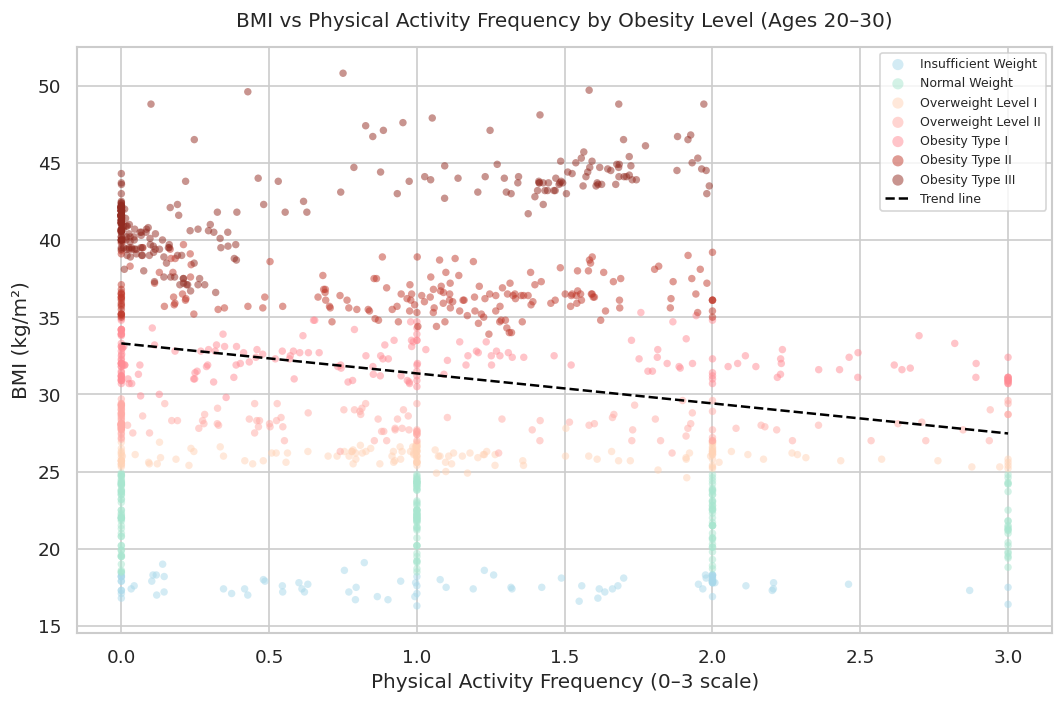

In [34]:
# Linear regression trend line using numpy polyfit
# Reference: NumPy documentation - numpy.polyfit
# https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html

fig, ax = plt.subplots(figsize=(9, 6))

palette = {
    'Insufficient_Weight': '#a8d8ea',
    'Normal_Weight':       '#a8e6cf',
    'Overweight_Level_I':  '#ffd3b6',
    'Overweight_Level_II': '#ffaaa5',
    'Obesity_Type_I':      '#ff8b94',
    'Obesity_Type_II':     '#c0392b',
    'Obesity_Type_III':    '#922b21'
}

for level in obesity_order:
    subset = df[df['Obesity_Level'] == level]
    ax.scatter(subset['Physical_Activity_Freq'], subset['BMI'],
               color=palette[level], label=level.replace('_', ' '),
               alpha=0.5, s=20, edgecolors='none')

# Add linear regression line
m, b = np.polyfit(df['Physical_Activity_Freq'], df['BMI'], 1)
x_line = np.linspace(df['Physical_Activity_Freq'].min(), df['Physical_Activity_Freq'].max(), 100)
ax.plot(x_line, m * x_line + b, color='black', linewidth=1.5, linestyle='--', label='Trend line')

ax.set_title('BMI vs Physical Activity Frequency by Obesity Level (Ages 20–30)', fontsize=12, pad=12)
ax.set_xlabel('Physical Activity Frequency (0–3 scale)')
ax.set_ylabel('BMI (kg/m²)')
ax.legend(fontsize=7.5, loc='upper right', markerscale=1.5)
plt.tight_layout()
plt.savefig('viz4_bmi_scatter.png', dpi=150)
plt.show()

**What this code does:**  
This cell creates a scatter plot of BMI against Physical Activity Frequency, with each point coloured according to its obesity level classification. A linear regression trend line is overlaid using `np.polyfit()` to show the overall directional relationship.

**Analysis:**  
The scatter plot is also a powerful visual representation of the relationship between physical inactivity and increased BMI. The downward sloping trend line indicates that as physical activity levels increase, BMI levels also decrease. The color-coded levels of obesity also demonstrate clear clustering. The blue and green colors, which represent insufficient and normal weight, respectively, are clustered in the region of higher physical activity and lower BMI, while the red and dark red colors, which represent different types of obesity, are clustered in the region of lower physical activity and higher BMI. However, it is also evident that there is considerable overlap in this region, indicating that physical activity levels are not solely responsible for obesity levels.

### Visualisation 5 — Heatmap: Correlation Matrix of Key Numerical Variables

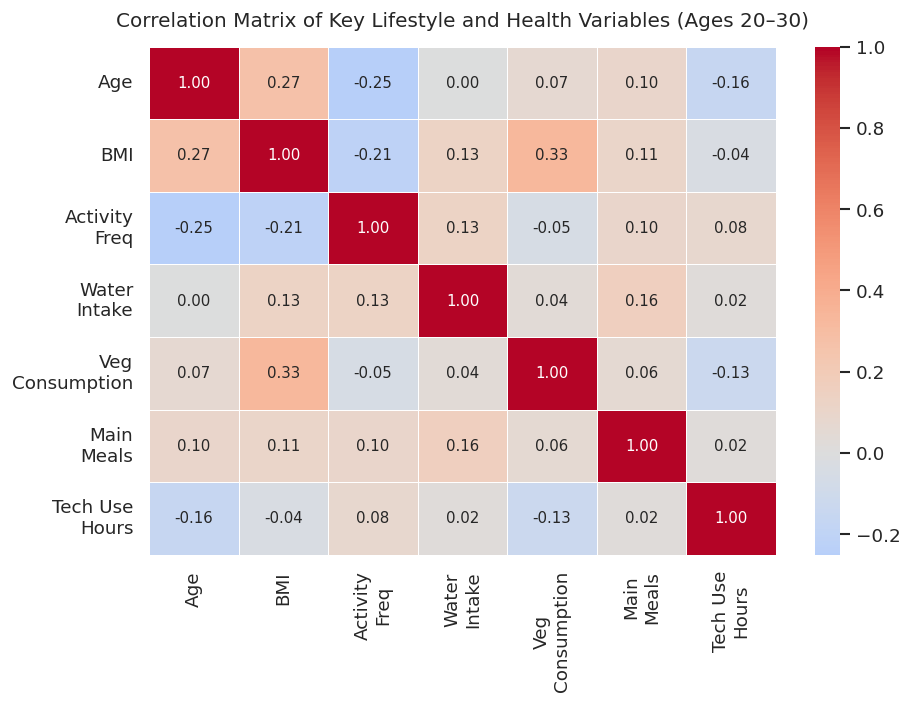

In [35]:
# Seaborn heatmap implementation
# Reference: seaborn documentation - seaborn.heatmap
# https://seaborn.pydata.org/generated/seaborn.heatmap.html

num_cols_heatmap = [
    'Age', 'BMI', 'Physical_Activity_Freq', 'Daily_Water_Intake',
    'Vegetable_Consumption_Freq', 'Num_Main_Meals', 'Technology_Use_Hours'
]

corr = df[num_cols_heatmap].corr()

# Rename for cleaner display on chart
display_labels = ['Age', 'BMI', 'Activity\nFreq', 'Water\nIntake',
                  'Veg\nConsumption', 'Main\nMeals', 'Tech Use\nHours']

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    linecolor='white',
    xticklabels=display_labels,
    yticklabels=display_labels,
    ax=ax,
    annot_kws={'size': 9}
)

ax.set_title('Correlation Matrix of Key Lifestyle and Health Variables (Ages 20–30)', fontsize=12, pad=12)
plt.tight_layout()
plt.savefig('viz5_correlation_heatmap.png', dpi=150)
plt.show()

**What this code does:**  
This cell computes the Pearson correlation matrix for seven key numerical variables and visualises it as an annotated heatmap using seaborn. The `coolwarm` colour palette maps positive correlations to red and negative correlations to blue, with values annotated in each cell. White grid lines separate each cell for clarity.

**Analysis:**  
The heatmap gives a complete picture of the relationships between all key variables at once. The most prominent relationship observed is the negative correlation between BMI and Physical Activity Frequency, which again follows the pattern observed in the earlier visualisations. BMI does not have a statistically significant correlation with Technology Use Hours (r = -0.035, p = 0.228), suggesting that screen time is not a useful predictor for BMI. Water intake and vegetable consumption have weak positive correlations with each other, possibly suggesting a cluster of 'healthy lifestyle' variables. Note that Age has a weak correlation with BMI in this tightly controlled age range, which is to be expected given the small ten-year window.

---
## Section 6: Analysis of Results


### Summary and Key Findings
This study set out to examine how everyday lifestyle choices, what young adults eat, how active they are, and how they get around, relate to obesity levels in the 20 to 30 age group. The original dataset had 2,111 records, but after cleaning process that involved renaming columns, dropping duplicates, filtering for the target age group, flagging extreme values through the IQR method, and adding a calculated BMI column, the working dataset came down to 1,197 participants.

In Visualisation 1, the histogram showed a clear rightward skew, far from the bell curve you might expect in a healthy population. With a mean BMI of 31.5 kg/m², the sample sits firmly in the obese range by WHO standards, which sets the healthy upper limit at 25 kg/m². For a group typically considered to be in their physical prime, this is a striking result.

Visualisation 2 broke this down further by gender and obesity category. The bar chart showed a steady climb in average BMI from Insufficient Weight through to Obesity Type III across both sexes. One interesting pattern that stood out was that males tended to record higher BMIs at the severe end of the spectrum, while females showed marginally higher values at the lower classifications, a gender difference worth exploring in future research.

The box plot in Visualisation 3 told a consistent story: the more severe the obesity classification, the lower the physical activity levels. Participants in the Obesity Type II and III categories had median activity scores that were close to zero, which contrasts sharply with those at the healthier end of the scale.

Visualisation 4 put numbers to this pattern. The Pearson correlation between BMI and physical activity came out at r = -0.206 (p < 0.0001), and a simple linear regression showed that each unit increase in activity corresponded to a 1.93 kg/m² drop in BMI. The R² of 0.043 suggests activity accounts for roughly 4.3% of BMI variation — meaningful, but clearly not the whole picture.

Finally, the heatmap in Visualisation 5 revealed that water intake had a small but significant positive correlation with BMI (r = 0.128, p < 0.0001), most likely because heavier individuals simply consume more overall. Screen time showed no meaningful link to BMI (p = 0.228). A one-way ANOVA confirmed that BMI differences across all seven obesity groups were highly significant (F = 4783, p < 0.0001).

Overall, the data points to physical inactivity as the single strongest lifestyle-related predictor of higher BMI in this age group, a finding that has clear relevance for students and young professionals spending long hours sitting down.


**Word count: 432**
